# MEMBER5 - Feature Engineering - Feature Selection

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 79 features + `SalePrice`)  
**Task:** predict the sale price of a house (regression).  
Run this notebook from the `notebooks/` folder so the `../data/raw/` paths resolve.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
print('train:', df.shape, '| test:', test.shape)
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Correlation of numeric features with the (log) target

In [2]:
num = df.select_dtypes(include='number').drop(columns=['Id', 'MSSubClass'])
num['LogPrice'] = np.log1p(num['SalePrice'])
num = num.drop(columns='SalePrice')
target_corr = num.corr()['LogPrice'].drop('LogPrice')
print('Numeric features:', len(target_corr))
target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(10).round(3)

Numeric features: 35


OverallQual     0.817
GrLivArea       0.701
GarageCars      0.681
GarageArea      0.651
TotalBsmtSF     0.612
1stFlrSF        0.597
FullBath        0.595
YearBuilt       0.587
YearRemodAdd    0.566
GarageYrBlt     0.541
Name: LogPrice, dtype: float64

## 2. Redundancy: highly correlated feature pairs (|r| > 0.8)

When two features carry almost the same information, keep the one more related to the target and drop the other.

In [3]:
feat = num.drop(columns='LogPrice')
corr = feat.corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.8]
to_drop_redundant = []
for a, b, r in pairs:
    loser = a if abs(target_corr[a]) < abs(target_corr[b]) else b
    to_drop_redundant.append(loser)
    print(f'{a:13s} vs {b:13s} r={r:.2f} -> drop {loser}')
to_drop_redundant = sorted(set(to_drop_redundant))

YearBuilt     vs GarageYrBlt   r=0.83 -> drop GarageYrBlt
TotalBsmtSF   vs 1stFlrSF      r=0.82 -> drop 1stFlrSF
GrLivArea     vs TotRmsAbvGrd  r=0.83 -> drop TotRmsAbvGrd
GarageCars    vs GarageArea    r=0.88 -> drop GarageArea


## 3. Relevance: drop features almost unrelated to price (|r| < 0.05)

In [4]:
irrelevant = target_corr[target_corr.abs() < 0.05].index.tolist()
selected = [c for c in feat.columns if c not in to_drop_redundant and c not in irrelevant]
print('Dropped as redundant :', to_drop_redundant)
print('Dropped as irrelevant:', irrelevant)
print('Kept', len(selected), 'of', feat.shape[1], 'numeric features')
os.makedirs('../results/outputs', exist_ok=True)
pd.DataFrame({'selected_numeric_feature': selected}).to_csv('../results/outputs/selected_numeric_features.csv', index=False)

Dropped as redundant : ['1stFlrSF', 'GarageArea', 'GarageYrBlt', 'TotRmsAbvGrd']
Dropped as irrelevant: ['OverallCond', 'BsmtFinSF2', 'LowQualFinSF', 'BsmtHalfBath', 'MiscVal', 'YrSold']
Kept 25 of 35 numeric features


## 4. EDA visualizations

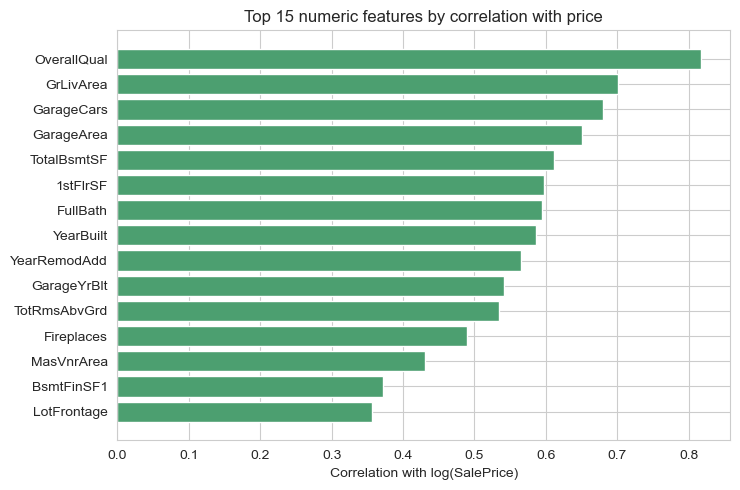

In [5]:
os.makedirs('../results/eda_visualizations/FeatureSelection', exist_ok=True)
top = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(15)[::-1]
plt.figure(figsize=(7.5, 5))
plt.barh(top.index, top.values, color=['#4C9F70' if v > 0 else '#E06C75' for v in top.values])
plt.xlabel('Correlation with log(SalePrice)'); plt.title('Top 15 numeric features by correlation with price')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/FeatureSelection/target_correlation_bar.png', dpi=120); plt.show()

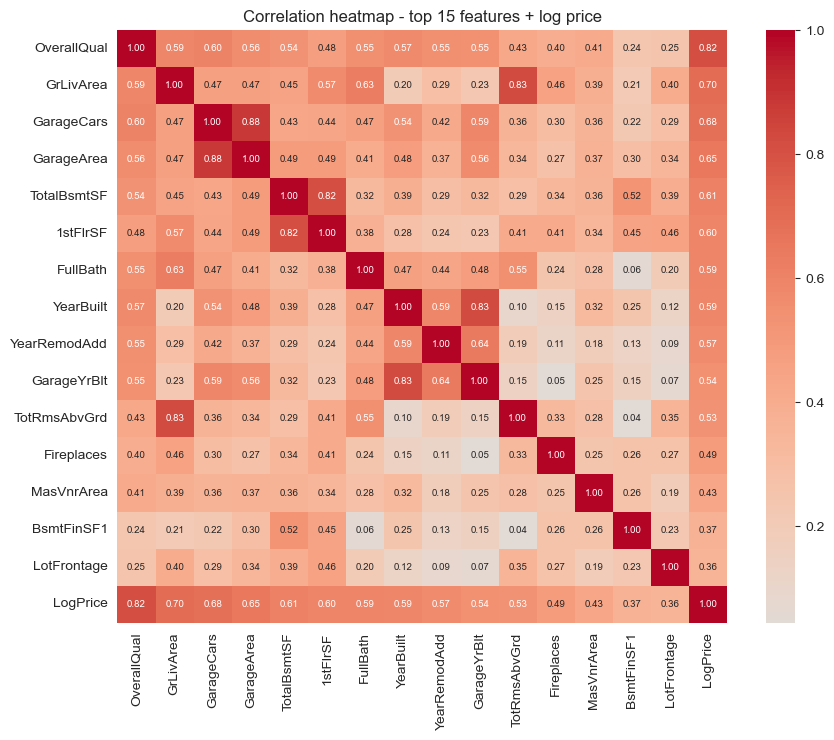

In [6]:
cols15 = target_corr.abs().sort_values(ascending=False).head(15).index.tolist() + ['LogPrice']
plt.figure(figsize=(9, 7.5))
sns.heatmap(num[cols15].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation heatmap - top 15 features + log price')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/FeatureSelection/correlation_heatmap.png', dpi=120); plt.show()

## 5. Does selection hurt? (Ridge, 5-fold CV RMSLE, numeric features only)

All 35 numeric features : RMSLE 0.1607
Selected 25 features    : RMSLE 0.1672


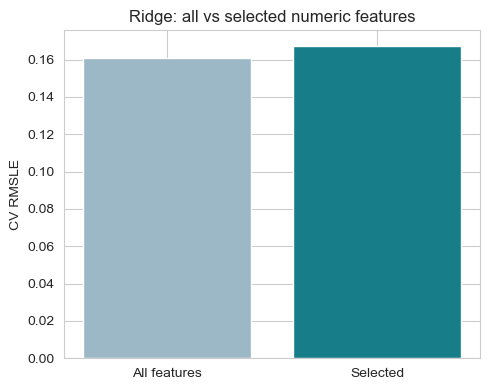

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, KFold

y = num['LogPrice']; cv = KFold(5, shuffle=True, random_state=42)
def score(cols):
    p = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10))
    return -cross_val_score(p, feat[cols], y, cv=cv, scoring='neg_root_mean_squared_error').mean()
s_all, s_sel = score(feat.columns.tolist()), score(selected)
print(f'All {feat.shape[1]} numeric features : RMSLE {s_all:.4f}')
print(f'Selected {len(selected)} features    : RMSLE {s_sel:.4f}')
plt.figure(figsize=(5, 4)); plt.bar(['All features', 'Selected'], [s_all, s_sel], color=['#9CB7C5', '#177E89'])
plt.ylabel('CV RMSLE'); plt.title('Ridge: all vs selected numeric features')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/FeatureSelection/selected_vs_all_cv.png', dpi=120); plt.show()

### Interpretation

Overall quality (`OverallQual`, r = 0.82), living area (`GrLivArea`), garage size and basement/floor area are the strongest numeric predictors of log price. Four pairs of features are almost duplicates (garage cars/area, basement/first-floor area, rooms/living area, year built/garage year built), so the weaker member of each pair was dropped; six features with almost no correlation to price (`OverallCond`, `BsmtFinSF2`, `LowQualFinSF`, `BsmtHalfBath`, `MiscVal`, `YrSold`) were also removed, leaving **25 of 35** numeric features. The validation step shows the trade-off honestly: a Ridge model on the reduced set has a cross-validated RMSLE of 0.167 versus 0.161 for all 35 features, i.e. a small loss in accuracy for 29 % fewer inputs. This is partly because correlation only captures *linear* relationships (e.g. `OverallCond` has a weak linear but a real non-linear effect), so the tree models in the model notebooks keep all columns and let the algorithm decide.